# Betting on Visitors: does more tourism mean more gaming revenue in Macau?
**Region:** Macau SAR, China · **Domain:** gaming (casino) industry and tourism economy · **Period:** 2010–2025

**Research question:** Does Macau's gross gaming revenue (GGR) rise and fall in step with the number of visitors, or has the gaming revenue each visitor brings in changed over time, especially since COVID-19?

This notebook walks through the proposal one small step at a time. Each cell does one thing, so you can run it top to bottom and see exactly where every number and every piece of the chart comes from.

| Proposal section | Notebook part |
|---|---|
| 1. Research question | Part 0 (this cell) |
| 2. Datasets | Part 1: load and check the data |
| 3. Preliminary visualization | Parts 2–4: build the measures, check the correlation, draw Figure 1 |
| (added for the portfolio) | Part 5: draw Figure 2, where the correlation comes from |
| 3. Justification | Part 6: the numbers quoted in the write-up |
| 6. Criteria for success | Part 7: reproducibility check |

**Data sources**
- Gaming Inspection and Coordination Bureau (DICJ), *Gaming Statistics – gross revenue from games of chance*: https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/index.html
- Statistics and Census Service (DSEC), *Visitor Arrivals*: https://www.dsec.gov.mo/en-US/Statistic?id=402
- Macao Government Tourism Office, *Macao Tourism Data Plus* (cross-check): https://dataplus.macaotourism.gov.mo/

The annual totals are compiled in `data/macau_ggr_visitors.csv` (GGR in MOP billion, visitor arrivals in millions).

## Part 1 · Load the data and make sure it's sound

**Step 1.** Import the libraries. Only pandas and matplotlib are needed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

**Step 2.** Read the CSV from the `data/` folder next to this notebook.

In [2]:
df = pd.read_csv('data/macau_ggr_visitors.csv')

**Step 3.** Take a first look: one row per year, GGR and visitor arrivals side by side.

In [3]:
df

,year,ggr_mop_billion,visitor_arrivals_million
0,2010,188.34,24.97
1,2011,267.87,28.00
2,2012,304.14,28.08
3,2013,360.75,29.32
4,2014,351.52,31.53
5,2015,231.01,30.71
6,2016,223.21,30.95
7,2017,265.74,32.61
8,2018,302.85,35.80
9,2019,292.46,39.41


**Step 4.** Quick sanity check: we expect 16 years (2010–2025), no gaps and no missing values. If any of these fails, the rest of the analysis shouldn't be trusted.

In [4]:
assert len(df) == 16
assert df['year'].tolist() == list(range(2010, 2026))
assert df.notna().all().all()
print('Data check passed: 16 consecutive years, no missing values.')

Data check passed: 16 consecutive years, no missing values.


**Step 5.** Put the year in the index so we can look rows up by year, e.g. `yr.loc[2019]`.

In [5]:
yr = df.set_index('year')

**Step 6.** The headline that started this project: compare 2019 (the last normal year) with 2025.

In [6]:
yr.loc[[2019, 2025]]

,ggr_mop_billion,visitor_arrivals_million
year,,
2019,292.46,39.41
2025,247.40,40.07


So visitors are back to a record, but GGR is still well under 2019. That gap is what the rest of the notebook digs into.

## Part 2 · Build the three measures used in Figure 1

**Step 7.** GGR per visitor arrival, in MOP. Convert both columns to plain units first (billion → ×10⁹, million → ×10⁶), then divide.

In [7]:
df['ggr_per_visitor_mop'] = df['ggr_mop_billion'] * 1e9 / (df['visitor_arrivals_million'] * 1e6)

**Step 8.** Pick 2019 as the base year. It's the last full year before the pandemic, so it's the natural "normal" to compare against.

In [8]:
base = df.set_index('year').loc[2019]
base

ggr_mop_billion              292.460000
visitor_arrivals_million      39.410000
ggr_per_visitor_mop         7420.959147
Name: 2019, dtype: float64

**Step 9.** Index GGR to 2019 = 100. An index lets two series with different units share one axis, so we don't need a (misleading) dual-axis chart.

In [9]:
df['ggr_index'] = df['ggr_mop_billion'] / base['ggr_mop_billion'] * 100

**Step 10.** Do the same for visitor arrivals.

In [10]:
df['visitor_index'] = df['visitor_arrivals_million'] / base['visitor_arrivals_million'] * 100

**Step 11.** Refresh the year-indexed view so it includes the new columns, then look at the full table.

In [11]:
yr = df.set_index('year')
df.round(1)

,year,ggr_mop_billion,visitor_arrivals_million,ggr_per_visitor_mop,ggr_index,visitor_index
0,2010,188.3,25.0,7542.7,64.4,63.4
1,2011,267.9,28.0,9566.8,91.6,71.0
2,2012,304.1,28.1,10831.2,104.0,71.3
3,2013,360.8,29.3,12303.9,123.4,74.4
4,2014,351.5,31.5,11148.7,120.2,80.0
5,2015,231.0,30.7,7522.3,79.0,77.9
6,2016,223.2,31.0,7212.0,76.3,78.5
7,2017,265.7,32.6,8149.0,90.9,82.7
8,2018,302.8,35.8,8459.5,103.6,90.8
9,2019,292.5,39.4,7421.0,100.0,100.0


## Part 3 · Do GGR and visitors move together? (correlation)

**Step 12.** Split off the pre-COVID years, 2010–2019.

In [12]:
pre = df[df['year'] <= 2019]

**Step 13.** Correlation before COVID. If "more tourists = more casino money" were true, this would be high.

In [13]:
r_pre = pre['ggr_mop_billion'].corr(pre['visitor_arrivals_million'])
print(f'2010-2019: r = {r_pre:.2f}')

2010-2019: r = 0.31


**Step 14.** Correlation over the whole period, 2010–2025.

In [14]:
r_all = df['ggr_mop_billion'].corr(df['visitor_arrivals_million'])
print(f'2010-2025: r = {r_all:.2f}')

2010-2025: r = 0.83


**Step 15.** Why does it jump so much? Drop the three pandemic years (2020–2022) and check again. If r falls back down, the high full-period value is mostly the pandemic crashing both series at the same time.

In [15]:
no_covid = df[~df['year'].between(2020, 2022)]
r_no_covid = no_covid['ggr_mop_billion'].corr(no_covid['visitor_arrivals_million'])
print(f'2010-2025 without 2020-2022: r = {r_no_covid:.2f}')

2010-2025 without 2020-2022: r = 0.19


Takeaway: the strong full-period correlation is a pandemic effect, not proof that visitor numbers drive gaming revenue.

## Part 4 · Draw Figure 1, piece by piece

**Step 16.** Set the colours and a clean, light style.

In [16]:
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2})

**Step 17.** Create two stacked panels that share the year axis: the top one for the two indices, the bottom one for GGR per visitor.

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8.2), sharex=True,
                               gridspec_kw={'height_ratios': [1.25, 1], 'hspace': 0.28}, facecolor=SURF)
plt.close(fig)  # hold off displaying it; we'll show it with `fig` whenever we want a look

**Step 18.** Tidy both panels: light horizontal gridlines, no box, and a grey band marking the 2020–2022 pandemic years.

In [18]:
for ax in (ax1, ax2):
    ax.set_facecolor(SURF)
    ax.grid(axis='y', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.axvspan(2019.5, 2022.5, color='#efeeea', zorder=0)

**Step 19.** Top panel: plot the visitor index.

In [19]:
ax1.plot(df['year'], df['visitor_index'], color=BLUE, lw=2, marker='o', ms=5, mec=SURF, mew=1.5, label='Visitor arrivals');

**Step 20.** Top panel: plot the GGR index on the same scale.

In [20]:
ax1.plot(df['year'], df['ggr_index'], color=ORANGE, lw=2, marker='o', ms=5, mec=SURF, mew=1.5, label='Gross gaming revenue');

**Step 21.** Add a dashed line at 100 (= the 2019 level) and fix the y-range.

In [21]:
ax1.hlines(100, 2009.5, 2025, color=INK2, lw=0.8, ls=(0, (3, 3)))
ax1.set_ylim(0, 135);

Let's peek at the figure so far. The two lines already tell most of the story.

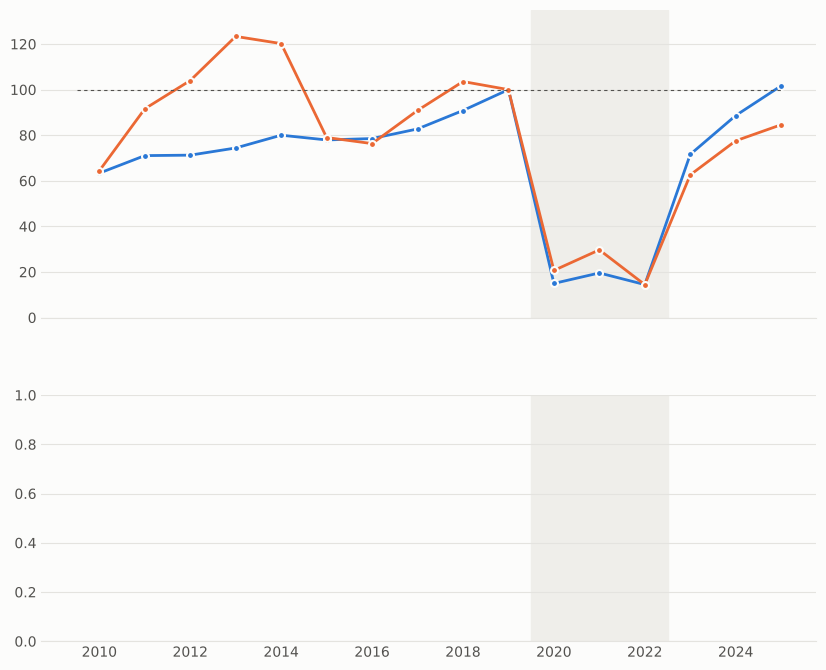

In [22]:
fig

**Step 22.** Label the 2025 end points directly, so nobody has to hunt through a legend for the final values.

In [23]:
last = df.iloc[-1]
ax1.text(2025.25, last['visitor_index'], f"Visitors {last['visitor_index']:.0f}", color=INK, va='center', fontsize=9.5, fontweight='bold')
ax1.text(2025.25, last['ggr_index'], f"GGR {last['ggr_index']:.0f}", color=INK, va='center', fontsize=9.5, fontweight='bold');

**Step 23.** Annotate the two key events: the 2013 VIP peak and the COVID border closures.

In [24]:
ax1.text(2013, 126, 'GGR peak\n(VIP era)', color=INK2, ha='center', fontsize=8.5)
ax1.text(2021, 118, 'COVID-19\nborder closures', color=INK2, ha='center', fontsize=8.5);

**Step 24.** Top panel title, subtitle, y-label and legend. The title states the finding, not just the topic.

In [25]:
ax1.set_ylabel('Index, 2019 = 100')
ax1.set_title('Visitors are back to 2019 levels; gaming revenue is not', loc='left', fontsize=13, fontweight='bold', color=INK, pad=24)
ax1.text(0, 1.03, 'Macau annual gross gaming revenue and visitor arrivals, indexed to 2019', transform=ax1.transAxes, color=INK2, fontsize=9.5)
ax1.legend(loc='lower left', frameon=False, ncol=2, fontsize=9);

**Step 25.** Bottom panel: bars of GGR per visitor, the ratio the research question is really about.

In [26]:
ax2.bar(df['year'], df['ggr_per_visitor_mop'], color=ORANGE, width=0.7, edgecolor='none');

**Step 26.** Format the bottom panel: thousands separators, y-label, title and y-range.

In [27]:
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2.set_ylabel('MOP per visitor arrival')
ax2.set_title('Gross gaming revenue per visitor arrival (MOP)', loc='left', fontsize=11, fontweight='bold', color=INK)
ax2.set_ylim(0, 14500);

**Step 27.** Write the value on the three bars the write-up talks about: 2013 (peak), 2019 (pre-COVID), 2025 (latest).

In [28]:
for y in (2013, 2019, 2025):
    v = yr.loc[y, 'ggr_per_visitor_mop']
    ax2.text(y, v + 250, f'{v:,.0f}', ha='center', fontsize=9, color=INK, fontweight='bold')

**Step 28.** Show every year on the x-axis in short form ('10, '11, …).

In [29]:
ax2.set_xticks(range(2010, 2026))
ax2.set_xticklabels([f"'{str(y)[2:]}" for y in range(2010, 2026)]);

**Step 29.** Add the source line at the bottom. A chart without sources isn't finished.

In [30]:
fig.text(0.125, 0.045, 'Sources: DICJ (gross revenue from games of chance); DSEC (visitor arrivals). Shaded band: 2020-2022 pandemic years.',
         fontsize=8, color=INK2);

**Step 30.** Save the figure as a PNG in the `figures/` folder (this is Figure 1)…

In [31]:
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/fig1_ggr_vs_visitors_index.png', dpi=200, bbox_inches='tight', facecolor=SURF);

**Step 31.** …and show the finished version.

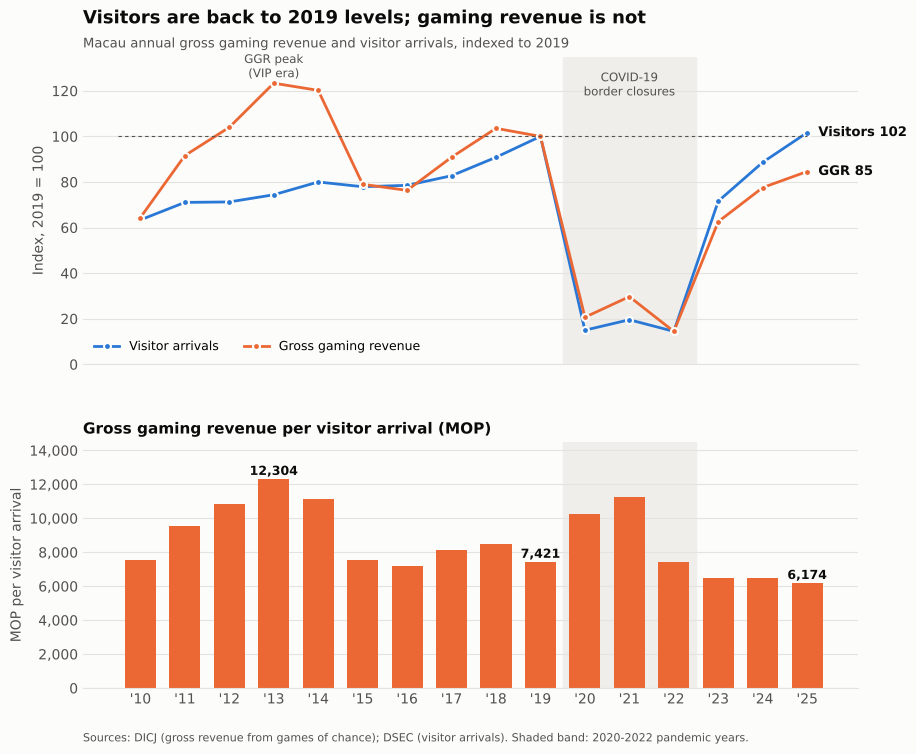

In [32]:
fig

## Part 5 · Draw Figure 2: where does the correlation come from?

**Step 32.** Group the years into three periods, so the scatter can colour them: before COVID, the pandemic years, and the recovery.

In [33]:
df['period'] = pd.cut(df['year'], bins=[2009, 2019, 2022, 2025],
                      labels=['2010–2019 (before COVID)', '2020–2022 (COVID)', '2023–2025 (recovery)'])
df['period'].value_counts(sort=False)

period
2010–2019 (before COVID)    10
2020–2022 (COVID)            3
2023–2025 (recovery)         3
Name: count, dtype: int64

**Step 33.** Draw a connected scatter: one dot per year, visitor arrivals on x and GGR on y. A faint line joins the years in time order so you can follow the path. Both axes start at zero.

In [34]:
PERIOD_COLORS = {'2010–2019 (before COVID)': BLUE, '2020–2022 (COVID)': '#a3a29b', '2023–2025 (recovery)': ORANGE}

fig2, ax = plt.subplots(figsize=(10, 6.6), facecolor=SURF)
plt.close(fig2)  # show it later with `fig2`
ax.set_facecolor(SURF)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)

ax.plot(df['visitor_arrivals_million'], df['ggr_mop_billion'], color=INK2, lw=0.9, alpha=0.35, zorder=1)
for period, color in PERIOD_COLORS.items():
    d = df[df['period'] == period]
    ax.scatter(d['visitor_arrivals_million'], d['ggr_mop_billion'], s=70, color=color,
               edgecolor=SURF, linewidth=1.5, zorder=3, label=period)
ax.set_xlim(0, 45)
ax.set_ylim(0, 400);

**Step 34.** Label every dot with its year (offsets are set by hand so labels don't collide), and write the three correlation coefficients from Part 3 on the chart itself.

In [35]:
LABEL_OFFSETS = {2010: (-9, 0), 2011: (-9, 0), 2012: (-9, 0), 2013: (-9, 3), 2014: (9, 0),
                 2015: (-9, 3), 2016: (6, -11), 2017: (9, 0), 2018: (-9, 4), 2019: (9, 0),
                 2020: (-9, 0), 2021: (9, 0), 2022: (-9, -3), 2023: (9, -4), 2024: (9, 0), 2025: (9, 0)}
for _, row in df.iterrows():
    dx, dy = LABEL_OFFSETS[row['year']]
    ax.annotate(str(row['year']), (row['visitor_arrivals_million'], row['ggr_mop_billion']),
                xytext=(dx, dy), textcoords='offset points', ha='right' if dx < 0 else 'left',
                va='center', fontsize=8.5, color=INK2)

rows = [('All years, 2010–2025', r_all), ('Before COVID, 2010–2019', r_pre), ('Without 2020–2022', r_no_covid)]
ax.text(0.03, 0.62, 'Correlation of visitors and GGR (r)', transform=ax.transAxes,
        fontsize=9.5, fontweight='bold', color=INK)
for k, (name, r) in enumerate(rows):
    y = 0.555 - k * 0.06
    ax.text(0.03, y, name, transform=ax.transAxes, fontsize=9.5, color=INK2)
    ax.text(0.325, y, f'{r:.2f}', transform=ax.transAxes, fontsize=9.5, color=INK,
            fontweight='bold', ha='right')

**Step 35.** Title that states the finding, axis labels, legend and source line. Then save it as Figure 2.

In [36]:
ax.set_title('The strong visitor–revenue link comes from the COVID crash',
             loc='left', fontsize=13, fontweight='bold', color=INK, pad=24)
ax.text(0, 1.03, 'Macau annual gross gaming revenue vs visitor arrivals, 2010–2025. Each dot is one year, joined in time order.',
        transform=ax.transAxes, color=INK2, fontsize=9.5)
ax.set_xlabel('Visitor arrivals (million)')
ax.set_ylabel('Gross gaming revenue (MOP billion)')
ax.legend(loc='upper left', frameon=False, fontsize=9)
fig2.text(0.125, 0.0, 'Sources: DICJ (gross revenue from games of chance); DSEC (visitor arrivals).',
          fontsize=8, color=INK2)
fig2.savefig('figures/fig2_correlation_scatter.png', dpi=200, bbox_inches='tight', facecolor=SURF);

**Step 36.** Show Figure 2. The three grey COVID dots sit far from everything else and drag the correlation up; the other thirteen years form a loose cloud with no clear line through it.

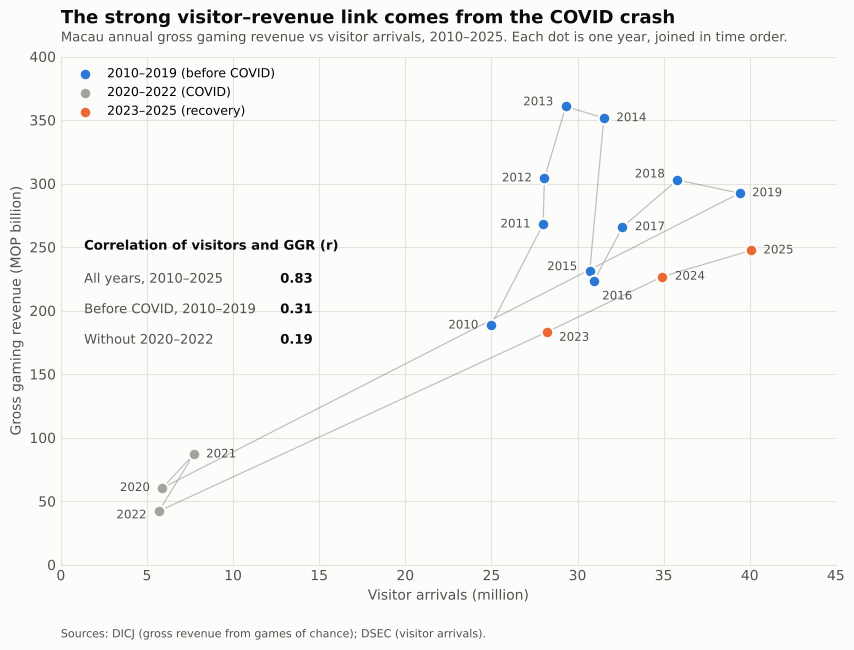

In [37]:
fig2

## Part 6 · The numbers quoted in the proposal

Every figure in the proposal's justification comes from one of the cells below, so the text and the data can't drift apart.

**Step 37.** 2025 vs 2019: visitors and GGR as a share of their 2019 levels.

In [38]:
r25 = yr.loc[2025]
print(f"2025 visitors: {r25['visitor_index']:.1f}% of 2019")
print(f"2025 GGR:      {r25['ggr_index']:.1f}% of 2019")

2025 visitors: 101.7% of 2019
2025 GGR:      84.6% of 2019


**Step 38.** GGR per visitor in the three benchmark years.

In [39]:
for y in (2013, 2019, 2025):
    print(f"{y}: MOP {yr.loc[y, 'ggr_per_visitor_mop']:,.0f} per visitor")

2013: MOP 12,304 per visitor
2019: MOP 7,421 per visitor
2025: MOP 6,174 per visitor


**Step 39.** How much less does each visitor bring in now than in 2019?

In [40]:
drop_vs_2019 = 1 - yr.loc[2025, 'ggr_per_visitor_mop'] / yr.loc[2019, 'ggr_per_visitor_mop']
print(f'GGR per visitor, 2025 vs 2019: {drop_vs_2019:.1%} lower')

GGR per visitor, 2025 vs 2019: 16.8% lower


**Step 40.** And compared with the 2013 peak?

In [41]:
drop_vs_2013 = 1 - yr.loc[2025, 'ggr_per_visitor_mop'] / yr.loc[2013, 'ggr_per_visitor_mop']
print(f'GGR per visitor, 2025 vs 2013 peak: {drop_vs_2013:.1%} lower')

GGR per visitor, 2025 vs 2013 peak: 49.8% lower


**Step 41.** The 2014–2015 anti-corruption campaign: how hard did GGR fall while visitors barely moved?

In [42]:
ggr_chg = yr.loc[2015, 'ggr_mop_billion'] / yr.loc[2014, 'ggr_mop_billion'] - 1
vis_chg = yr.loc[2015, 'visitor_arrivals_million'] / yr.loc[2014, 'visitor_arrivals_million'] - 1
print(f'2014 -> 2015: GGR {ggr_chg:+.1%}, visitors {vis_chg:+.1%}')

2014 -> 2015: GGR -34.3%, visitors -2.6%


**Step 42.** 2010–2013 VIP boom: GGR growth vs visitor growth over the same years.

In [43]:
ggr_boom = yr.loc[2013, 'ggr_mop_billion'] / yr.loc[2010, 'ggr_mop_billion'] - 1
vis_boom = yr.loc[2013, 'visitor_arrivals_million'] / yr.loc[2010, 'visitor_arrivals_million'] - 1
print(f'2010 -> 2013: GGR {ggr_boom:+.0%}, visitors {vis_boom:+.0%}')

2010 -> 2013: GGR +92%, visitors +17%


## Interpretation (preliminary)
So, does more tourism mean more gaming revenue? **Not really, or at least not any more.**

- **2010–2013, the VIP boom:** GGR almost doubled while visitor numbers grew by less than a fifth. High-roller VIP baccarat, not headcount, was doing the work, and revenue per visitor peaked at about MOP 12,300.
- **2014–2015, the crackdown:** the anti-corruption campaign knocked GGR down by about a third in one year, while visitors held roughly steady.
- **2020–2022, COVID:** both series collapsed together. That shared crash is what pushes the full-period correlation up to r ≈ 0.83; before COVID it was only r ≈ 0.31, and without the pandemic years it drops back again (Figure 2).
- **2025, the recovery:** visitors hit a record (≈102% of 2019), but GGR is only about 85% of 2019, so each visitor now brings in roughly 17% less gaming revenue than before the pandemic.

The link between visitors and gaming revenue is weaker than the headline recovery suggests. *Who* comes (same-day vs. overnight, mass vs. VIP after the 2021–22 junket crackdown) seems to matter as much as *how many* come. That's what the full project will test.

**Limitations:** only 16 annual points; correlation isn't causation; GGR is in nominal MOP (no inflation adjustment yet); visitor arrivals count trips, not unique people.

## Part 7 · Reproducibility check (success criterion)

**Step 43.** Confirm both figure files were written, so the notebook really does regenerate Figures 1 and 2 from the CSV.

In [44]:
import os
for f in ['figures/fig1_ggr_vs_visitors_index.png', 'figures/fig2_correlation_scatter.png']:
    assert os.path.exists(f), f'missing {f}'
print('Notebook ran top to bottom and regenerated both figures in figures/.')

Notebook ran top to bottom and regenerated both figures in figures/.
